# Classification of BRACS slides from UNI2-h embeddings

**Goal.** Train a PyTorch classifier that assigns each whole-slide image to one of the seven BRACS classes (N, PB, UDH, FEA, ADH, DCIS, IC) from the tile embeddings extracted in `01_wsi_to_vectors.ipynb`, and evaluate it with a complete set of metrics on the official Testing set.

**Approach.** A slide is a bag of tile embeddings with a single label (multiple-instance learning). Labels are not available for individual tiles, and a slide label is only the highest-grade region of the slide, so the unit of learning is the slide. Two models are trained: a **baseline** that averages the tile embeddings and classifies the mean with a linear layer, and a **gated attention multiple-instance model** (ABMIL, Ilse et al., 2018) that learns how much each tile contributes to the slide representation. The difference between them measures what learning tile weights adds.

**Pipeline.**
1. **Setup**: library versions, compute device and imports.
2. **Parameters**: paths, seeds and training settings.
3. **Data**: the official split, the bags of tile embeddings and the class weights.
4. **Models**: the baseline and the attention model.
5. **Training**: choice of the loss weighting on the Validation set, training of both models with several seeds.
6. **Evaluation on the Testing set**: confusion matrices, ROC and precision-recall curves, F1, calibration, clinical summaries and a paired comparison of the models.
7. **Interpretation**: attention over the tiles of selected slides.
8. **Summary and export**.

**Protocol.** The official Training, Validation and Testing split of BRACS is used unchanged. Training slides fit the models; Validation slides are used for every choice (loss weighting, epoch); Testing slides are used once, in section 6, after all choices are fixed. The code enforces that Testing slides never enter training or selection.

**Inputs / outputs.** Inputs: the per-slide `.pt` feature files in `FEATURES_DIR/<model>/` and `labels/BRACS.xlsx`. Results (tables and figures) are shown in the notebook and are not written to disk. The only output file is the best classifier, `classifier/classifier_model_<date-time>.pt`, with its weights, class names, feature scaler, settings and Validation result.

**Reproducibility.** One `SEED` fixes every random choice (initialisation, batch order, tile subsampling, bootstrap); the models are trained with several consecutive seeds and the results are reported for the average of their predictions and for the single seeds. The code is device-agnostic: it runs on a GPU when one is available and on the CPU otherwise. Library versions, device and all settings are printed here and saved in `config.json`.

## 1. Setup

### 1.1 Environment and library versions
Prints the Python and library versions used in this run, so results can be traced back to the software that produced them.

In [1]:
# STEP 1: Import general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


### 1.2 Compute device
Selects the device automatically: a GPU if one is available (CUDA, then Apple MPS), the CPU otherwise. No code in this notebook depends on a particular device. On a CUDA GPU the models run with bfloat16 mixed precision; on every other device they run in float32. Results on different devices can differ in the last digits, because floating-point operations are ordered differently, even with the same seed.

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


### 1.3 Imports
Imports the project's own building blocks from `utils/`: the label table, the loading of the bags, the models and their training, the metrics and the figures.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path
from time import time

# STEP 2: Import this project's own building blocks (data, models, training, metrics, figures)
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_models import build_model
from utils.mil_train import (compare_weightings, device_description, save_best_model, predict_ensemble, run_seeds, set_seed,
                             training_class_weights)
from utils.classification_metrics import (evaluate_predictions, paired_bootstrap, patient_bootstrap, per_seed_metrics,
                                          predictions_table, results_table)
from utils.plot_classification import (plot_attention, plot_bag_sizes, plot_calibration, plot_clinical_views, plot_confusion,
                                       plot_model_comparison, plot_per_class, plot_roc_pr, plot_training_curves)

## 2. Parameters
All paths and settings in one place. `SEED` is the base seed: run `i` of a model uses `SEED + i`, and the bootstrap uses `SEED` itself. The only file this notebook writes is the best classifier (section 8.2, `SAVE_BEST_MODEL`); every result is shown in the notebook only. `FEATURES_DIR` and `MODEL_NAME` locate the feature files written by notebook 01; `DATA_DIR` is only needed to show tiles in section 7. Training uses AdamW with a linear warm-up followed by cosine decay, gradient clipping, a random subset of at most `MAX_TILES_TRAIN` tiles per slide in every epoch (which also acts as regularisation) and early stopping on the Validation macro F1.

In [4]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features')   # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                           # STEP 2: Subfolder with the per-slide features
DATA_DIR = Path('/mnt/Data/bracs/data')                          # STEP 3: Slides (only used to show tiles in section 7)
LABELS_FILE = Path('labels/BRACS.xlsx')                          # STEP 4: Slide labels, patients and official split
MODEL_DIR = Path('classifier')                                   # STEP 5: Folder of the saved classifier (only used if SAVE_BEST_MODEL)
SAVE_BEST_MODEL = True                                           # STEP 5b: Save the best classifier as classifier_model_<date-time>.pt (the only file written)
SEED = 0                                                         # STEP 6: Base seed of every random choice
N_SEEDS = 5                                                      # STEP 7: Runs per model (seeds SEED, SEED + 1, ...)
EPOCHS, PATIENCE = 100, 20                                       # STEP 8: Maximum epochs and early-stopping patience
LR, WEIGHT_DECAY = 2e-4, 1e-2                                    # STEP 9: Peak learning rate and AdamW weight decay
BATCH_SIZE, MAX_TILES_TRAIN = 16, 2048                           # STEP 10: Slides per batch, tiles per slide in training
N_BOOT = 1000                                                    # STEP 11: Bootstrap resamples for the intervals
SEEDS = [SEED + i for i in range(N_SEEDS)]
set_seed(SEED)
TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE, max_tiles=MAX_TILES_TRAIN)

## 3. Data

### 3.1 Labels and the official split
Reads the label sheet into one table (slide, patient, class, official set). The classes are those of `BRACS.xlsx`, from benign to malignant: N, PB, UDH, FEA, ADH, DCIS and IC. The official split is used unchanged, so that results are comparable with published BRACS work; its properties (class mix of the sets, one patient with slides in Training and Validation, small Validation and Testing classes) are documented in `00_data_visualization.ipynb`.

In [5]:
# STEP 1: Label table with the official split
table = build_slide_table(LABELS_FILE)
table['set'].value_counts()

set
Training      395
Testing        87
Validation     65
Name: count, dtype: int64

### 3.2 Bags of tile embeddings
Loads the CLS embedding of every tile of every slide that has a feature file; the embeddings of a slide form a bag. Slides without a feature file or without tiles (for example slides that lack the pyramid level that was tiled) are dropped and reported by set, because they change the size of the Testing set. The tiling stored in the feature files (pyramid level, tile size, stride) is checked to be identical for all slides.

In [6]:
# STEP 1: Load the bags (float16) and check the tiling stored in the files
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

# STEP 2: The classes of the label sheet (the outputs of the models)
classes = data['classes']
print('Classes:', classes)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 546 of 547  |  tiles 93,627  |  tiles per slide: median 155, min 1, max 585  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 64/65, Testing 87/87
Dropped: 1 without a feature file, 0 without tiles (e.g. ['BRACS_1003660'])
Classes: ['N', 'PB', 'UDH', 'FEA', 'ADH', 'DCIS', 'IC']


### 3.3 Size of the bags
Number of tiles per slide in each set. Bag sizes differ by an order of magnitude, so batches are padded and masked, and long bags are subsampled during training.

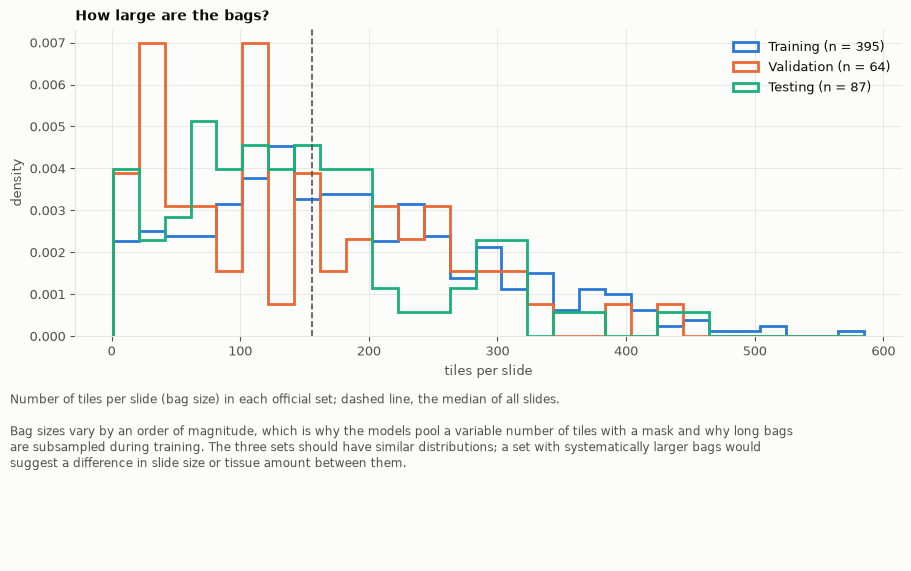

In [7]:
# STEP 1: Tiles per slide by set
bag_sizes = plot_bag_sizes(data)

### 3.4 Class weights
The classes are imbalanced (see `00_data_visualization.ipynb`), so a loss without weights favours the frequent classes. Weights are computed from the **Training** slides only, so that nothing about the Validation and Testing sets enters training. Two rules are compared in section 5.1 against no weighting: inverse frequency (every class contributes equally) and its square root (a milder correction).

In [8]:
# STEP 1: Weights per class from the Training counts, for each rule
weights = pd.DataFrame({m: training_class_weights(data, m).numpy() for m in ('sqrt', 'inverse')}, index=classes)
weights.insert(0, 'n_train', (data['table'][data['table']['set'] == 'Training']['label'].astype(str).value_counts().reindex(classes)).to_numpy())
weights.round(3)

,n_train,sqrt,inverse
N,27,1.516,2.090
PB,120,0.719,0.470
UDH,56,1.053,1.008
FEA,24,1.608,2.351
ADH,28,1.489,2.015
DCIS,40,1.245,1.411
IC,100,0.788,0.564


## 4. Models

### 4.1 Baseline: mean pooling and a linear layer
The embeddings of a slide are averaged and a single linear layer maps the mean to the seven class scores. The model has no notion of which tiles matter; it describes what the average tile of a slide looks like. It is the reference against which the attention model is judged.

### 4.2 Gated attention multiple-instance model (ABMIL)
Each tile embedding $h_k$ is first projected by a shared layer. A gated attention network scores every tile, $a_k = \mathrm{softmax}_k\big(w^\top[\tanh(V h_k)\odot\mathrm{sigm}(U h_k)]\big)$, the scores are normalised over the real tiles of the slide (padding is masked), and the slide vector is the attention-weighted sum $z=\sum_k a_k h_k$, which a linear layer maps to the class scores. The model can therefore concentrate on the few tiles that carry the diagnosis and ignore the rest, and its attention weights can be inspected (section 7). The number of outputs equals the number of classes in the label sheet.

In [9]:
# STEP 1: Build both models and compare their size
for name in ('linear', 'abmil'):
    model = build_model(name, data['dim'], len(classes))
    print(f'{name:>6}: {sum(p.numel() for p in model.parameters()):>9,} parameters, {len(classes)} outputs')

linear:    10,759 parameters, 7 outputs
 abmil: 1,053,448 parameters, 7 outputs


## 5. Training

### 5.1 Choice of the loss weighting (Validation set only)
Trains the attention model with no weights, square-root weights and inverse-frequency weights, three seeds each, and compares the best Validation macro F1 of each option. Macro F1 gives every class the same weight and is therefore the appropriate selection criterion under imbalance. The Validation set is small, so differences smaller than the spread over seeds should not be over-interpreted; the option with the highest mean is used for the final models. The Testing set is not touched.

In [10]:
# STEP 1: Compare the weightings on the Validation set (3 seeds each)
t0 = time()
ablation = compare_weightings(data, DEVICE, SEEDS[:3], **TRAIN_ARGS)
WEIGHTING = ablation.loc[0, 'weighting']
print(f'Selected weighting: {WEIGHTING}  ({time() - t0:.0f} s)')
ablation.round(3)

Selected weighting: inverse  (35 s)


,weighting,val_macro_f1_mean,val_macro_f1_sd,val_balanced_accuracy_mean,val_balanced_accuracy_sd
0,inverse,0.522,0.023,0.525,0.025
1,sqrt,0.515,0.009,0.508,0.005
2,none,0.470,0.017,0.470,0.013


### 5.2 Final training of both models
Trains the baseline and the attention model once per seed with the selected weighting. For every run the epoch with the best Validation macro F1 is kept and its weights are restored. Predictions of the several seeds are later averaged (an ensemble), which reduces the dependence on a single random initialisation.

In [11]:
# STEP 1: Class weights from the Training counts, for the selected rule
class_weights = training_class_weights(data, WEIGHTING)

# STEP 2: Train both models once per seed
runs = {}
for name in ('linear', 'abmil'):
    t0 = time()
    runs[name] = run_seeds(name, SEEDS, data, class_weights, DEVICE, verbose=False, **TRAIN_ARGS)
    best = [r['best']['val_macro_f1'] for r in runs[name]]
    print(f'{name:>6}: Validation macro F1 {np.mean(best):.3f} ± {np.std(best, ddof=1) if len(best) > 1 else 0:.3f} over {len(best)} seeds  ({time() - t0:.0f} s)')

linear: Validation macro F1 0.468 ± 0.035 over 5 seeds  (29 s)
 abmil: Validation macro F1 0.532 ± 0.022 over 5 seeds  (19 s)


### 5.3 Training curves
Training and Validation loss and Validation macro F1 per epoch, averaged over the seeds. They show whether the models have converged, how much they overfit and which epoch was selected.

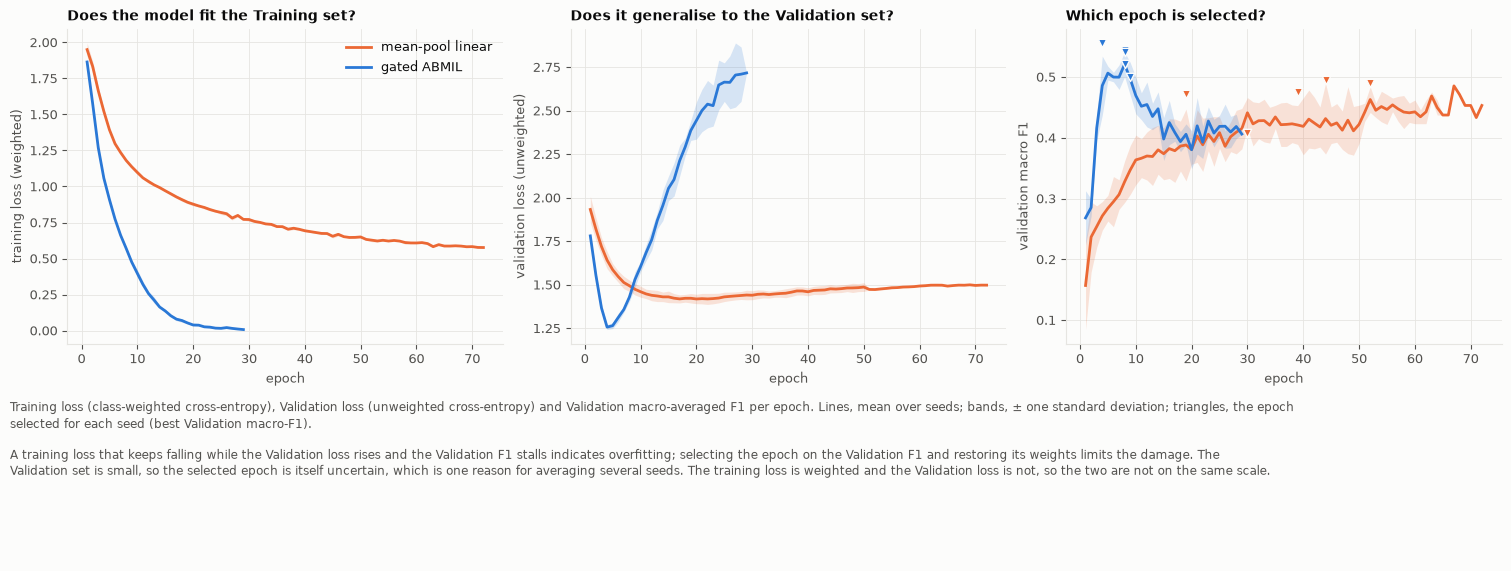

In [12]:
# STEP 1: Curves of every model (mean over seeds, band = one standard deviation)
curves = plot_training_curves({name: [r['history'] for r in rs] for name, rs in runs.items()})

## 6. Evaluation on the Testing set
From here on the Testing labels are used, once. No setting is changed after looking at these results; any new choice would have to be made on the Validation set and the evaluation repeated.

### 6.1 Predictions and metrics
Each model predicts the Testing slides with every tile of every slide, and the probabilities of the seeds are averaged. Reported measures (all computed from the class probabilities, one-vs-rest where a measure is binary):
- **Accuracy** and **balanced accuracy** (mean recall per class; insensitive to class frequency).
- **F1** per class, and its **macro** average (every class counts equally) and **weighted** average (weighted by class frequency).
- **AUROC** (area under the ROC curve; the probability that a slide of a class is ranked above a slide of another class) and **average precision** (area under the precision-recall curve), per class and macro-averaged.
- **Quadratic-weighted Cohen's kappa**, which penalises errors by their distance on the ordered scale of classes, and the **Matthews correlation coefficient**.
- **Log-loss**, **Brier score** and **expected calibration error** for the quality of the probabilities.

Intervals are 95% percentile intervals of a **patient-level bootstrap**: patients, with all of their slides, are resampled, because the slides of one patient are not independent. Classes that are missing from a resample are left out of that resample's macro averages.

In [13]:
# STEP 1: The Testing slides (first use of the Testing labels)
test = data['table'][data['table']['set'] == 'Testing'].reset_index(drop=True)
test_slides = test['slide'].tolist()
y_test = np.array([classes.index(str(l)) for l in test['label']])
patients = test['patient'].to_numpy()

# STEP 2: Seed-ensemble probabilities of every model (attention only for the attention model)
predictions = {name: predict_ensemble(rs, data, test_slides, DEVICE, attention=(name == 'abmil')) for name, rs in runs.items()}
proba = {name: p['proba'] for name, p in predictions.items()}

# STEP 3: All measures, bootstrap intervals and single-seed results
evaluations = {name: evaluate_predictions(y_test, proba[name], classes) for name in proba}
intervals = {name: patient_bootstrap(y_test, proba[name], patients, N_BOOT, SEED, per_class=True) for name in proba}
per_seed = {name: per_seed_metrics(y_test, predictions[name]['per_seed']) for name in proba}
paired = paired_bootstrap(y_test, proba['abmil'], proba['linear'], patients, N_BOOT, SEED)

# STEP 4: One table with every measure (ensemble value [95% interval]; single seeds as mean ± sd)
results = results_table(evaluations, {n: intervals[n]['ci'] for n in intervals}, per_seed)
results

,linear,linear (seeds),abmil,abmil (seeds)
accuracy,"0.345 [0.232, 0.484]",0.336 ± 0.005,"0.437 [0.322, 0.571]",0.434 ± 0.010
balanced_accuracy,"0.292 [0.225, 0.394]",0.282 ± 0.005,"0.409 [0.291, 0.506]",0.407 ± 0.020
macro_f1,"0.284 [0.222, 0.341]",0.274 ± 0.006,"0.386 [0.270, 0.456]",0.380 ± 0.015
macro_auroc,"0.688 [0.625, 0.766]",0.688 ± 0.003,"0.805 [0.733, 0.870]",0.798 ± 0.013
macro_ap,"0.336 [0.324, 0.443]",0.338 ± 0.008,"0.431 [0.376, 0.584]",0.423 ± 0.014
quadratic_kappa,"0.627 [0.478, 0.745]",0.625 ± 0.010,"0.701 [0.524, 0.847]",0.687 ± 0.039
mcc,"0.232 [0.114, 0.364]",0.221 ± 0.006,"0.339 [0.198, 0.483]",0.336 ± 0.015
weighted_f1,0.343,,0.418,
macro_precision,0.296,,0.382,
macro_recall,0.292,,0.409,


### 6.2 Confusion matrices
Rows are the true classes and columns the predicted classes. The diagonal is correct classifications; mass next to the diagonal is confusion between neighbouring grades, which is expected from the graded nature of the classes and from the known disagreement between pathologists.

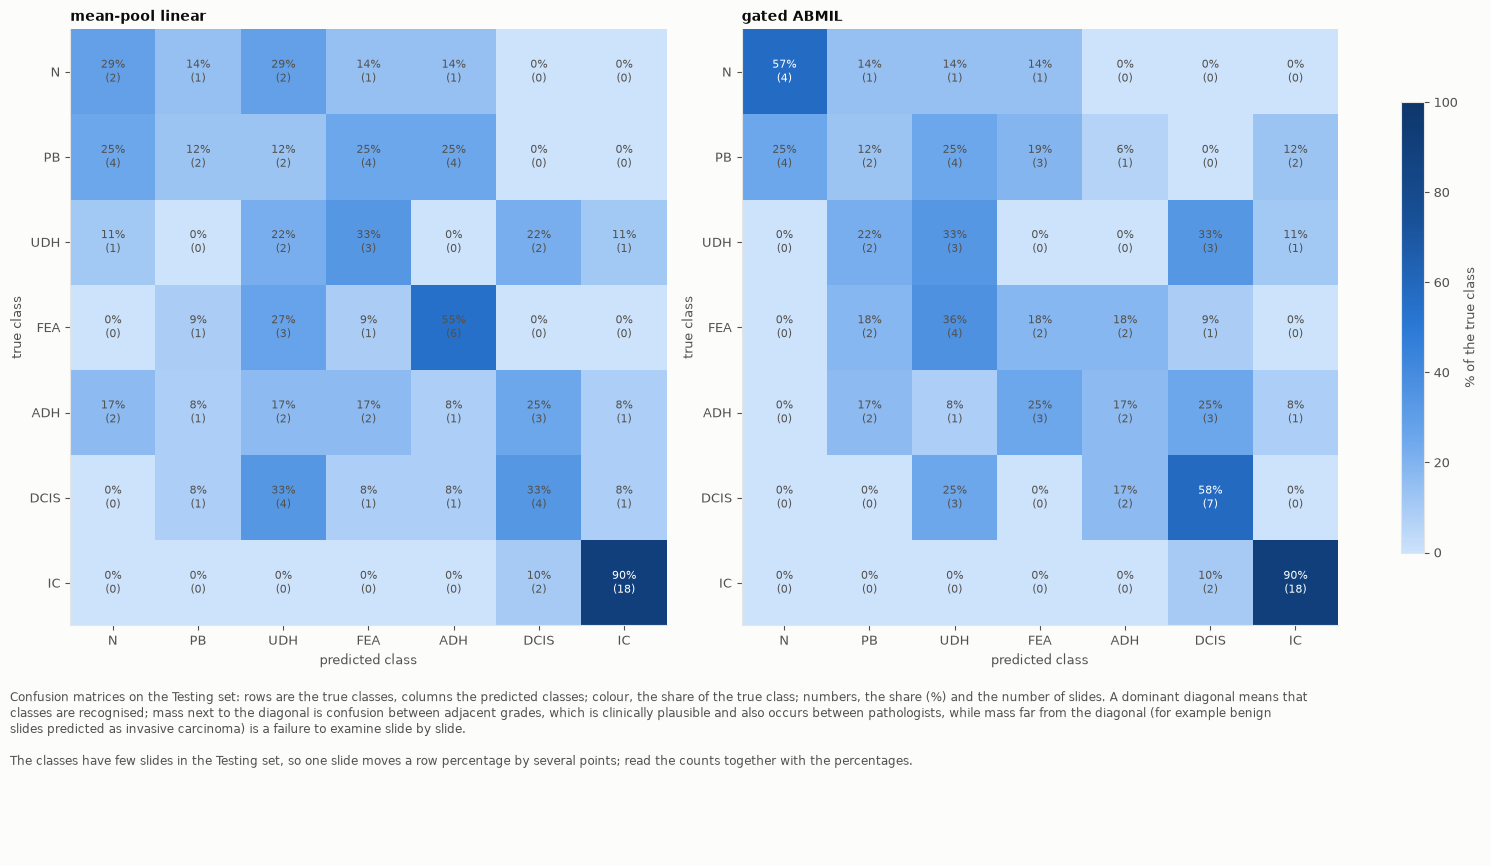

In [14]:
# STEP 1: Confusion matrix of each model on the Testing set
confusion = plot_confusion({name: e['confusion'] for name, e in evaluations.items()})

### 6.3 ROC and precision-recall curves
One-vs-rest curves for every class. The ROC curve and its area (AUROC) describe how well a class is ranked above the others independently of the decision threshold and of the class frequency; the precision-recall curve and the average precision depend on the class frequency, so they are shown next to it for the imbalanced classes.

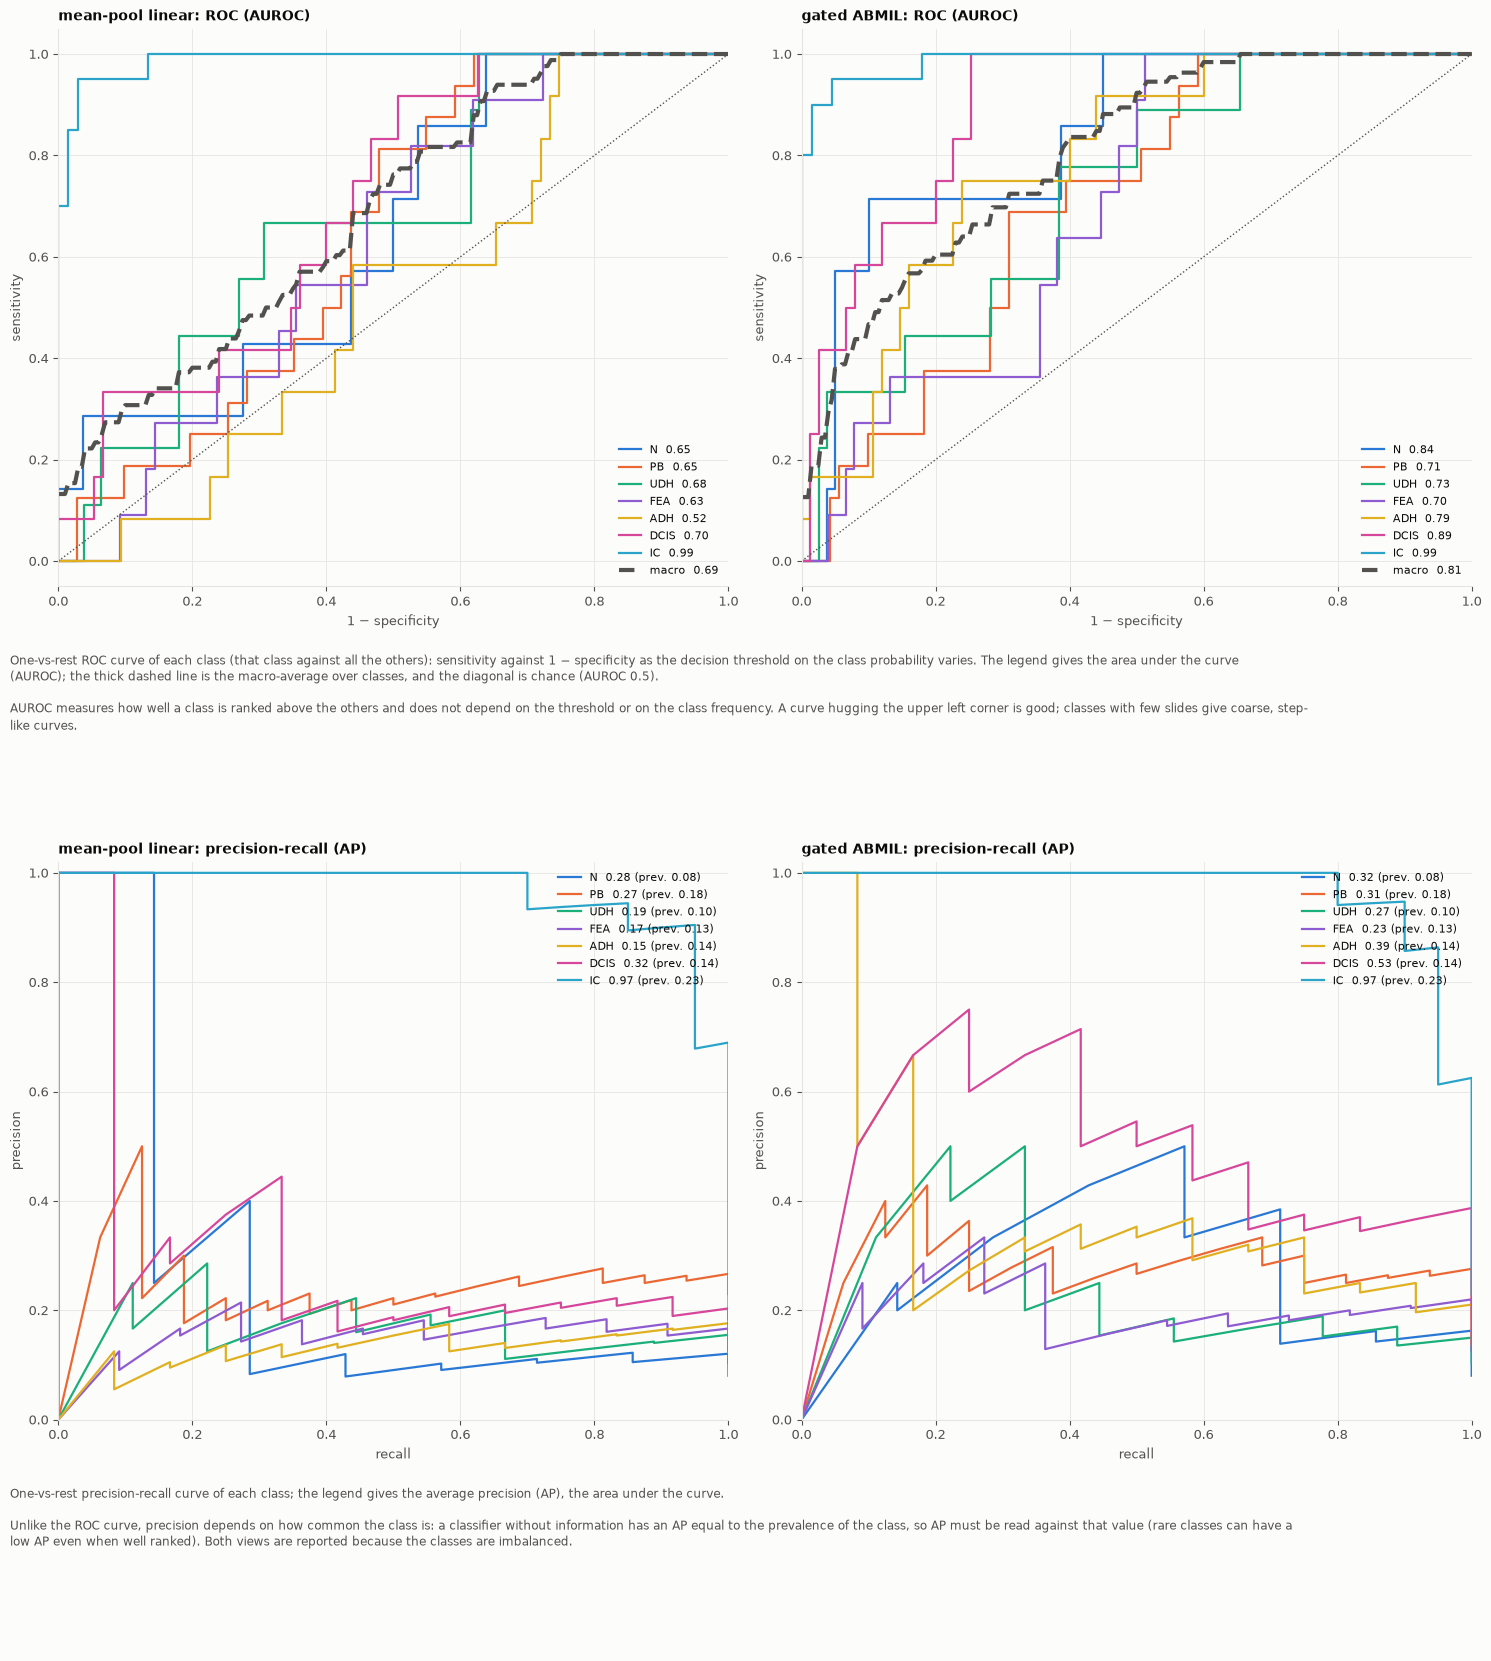

In [15]:
# STEP 1: ROC (top) and precision-recall (bottom) curves of every class and model
curves_roc_pr = plot_roc_pr(y_test, proba, classes)

### 6.4 Per-class results
F1 and AUROC of each class with patient-bootstrap intervals, and the number of Testing slides of each class. The intervals show how little can be concluded for the small classes.

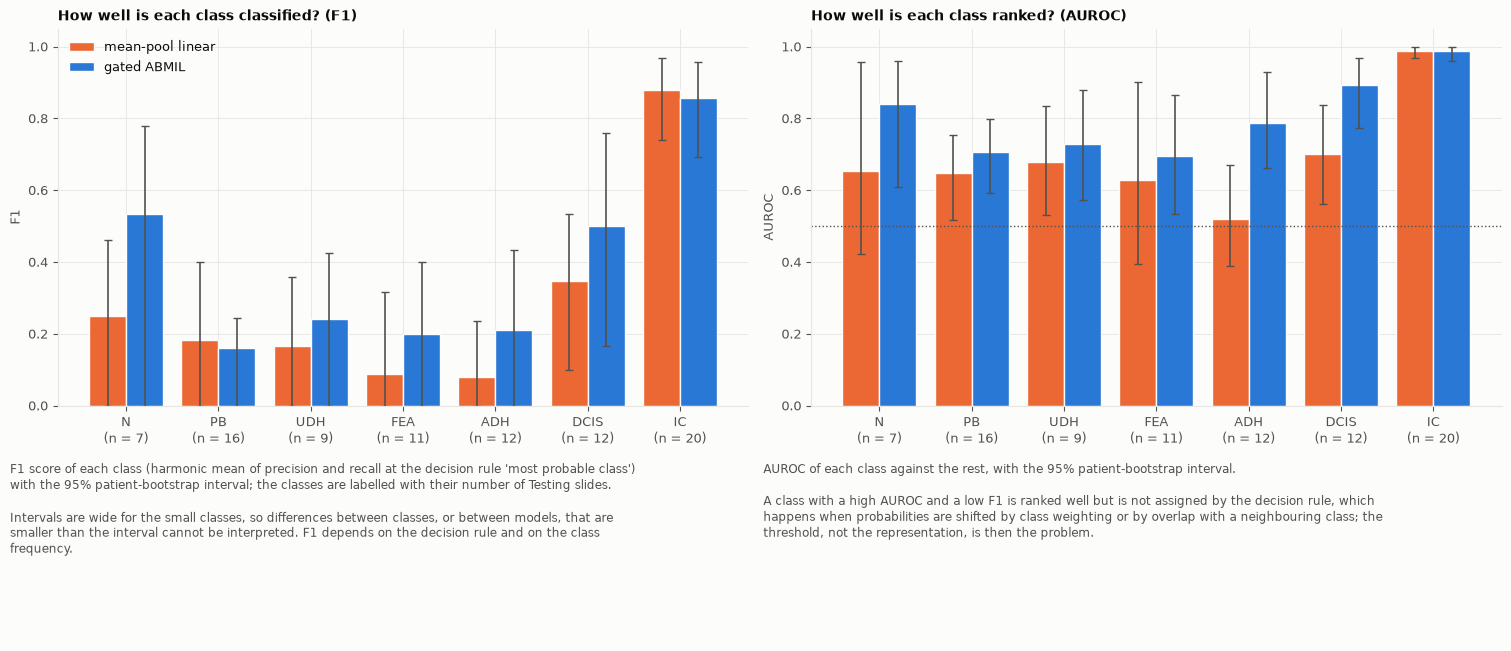

In [16]:
# STEP 1: F1 and AUROC per class with 95% intervals
per_class = plot_per_class({name: e['per_class'] for name, e in evaluations.items()}, intervals)

### 6.5 Calibration
Whether the probabilities of the models can be read as frequencies. The class weighting shifts probability towards the rare classes on purpose, so calibration with respect to the true class frequencies is not expected; the diagram shows how large the effect is and whether the models are overconfident.

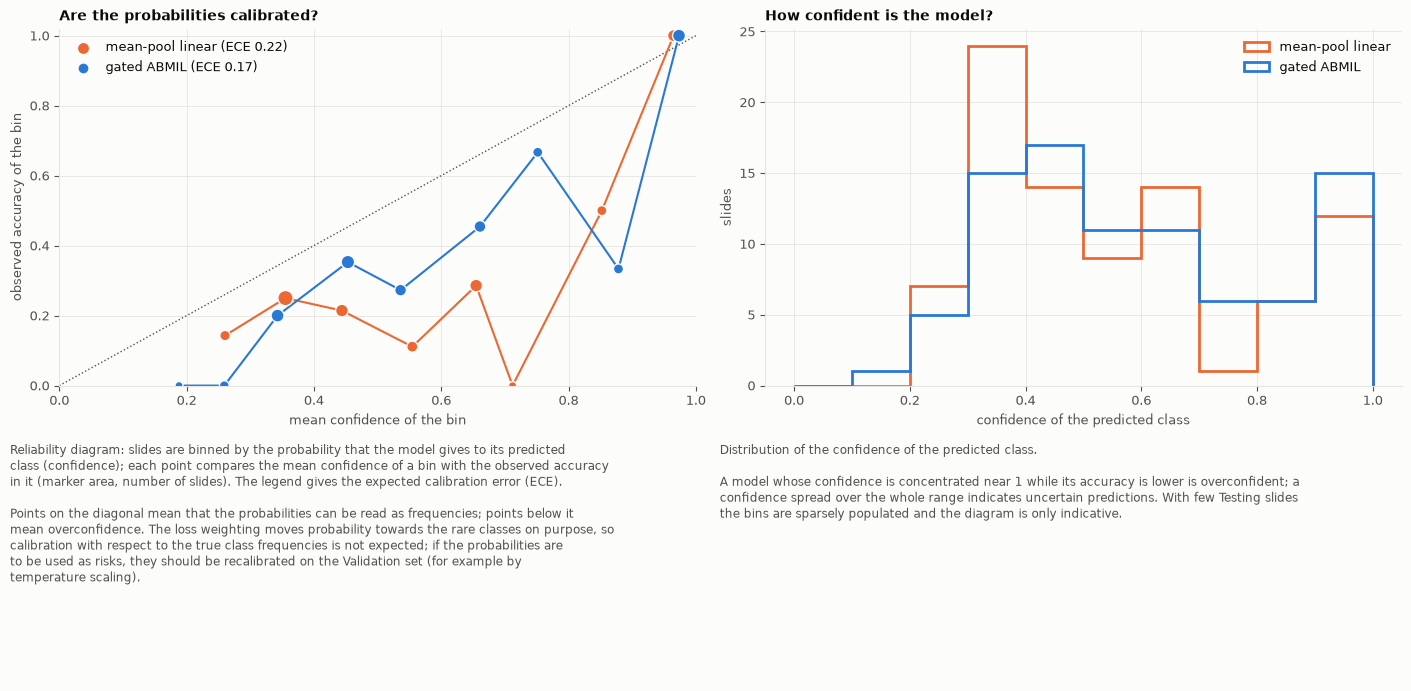

In [17]:
# STEP 1: Reliability diagram and confidence histogram
calibration = plot_calibration(y_test, proba)

### 6.6 Clinical summaries
The seven-class probabilities are summed into two clinically motivated views, without any new training: three tiers (benign: N, PB, UDH; atypical: FEA, ADH; malignant: DCIS, IC) and cancer (DCIS or IC) against everything else. The second is the clinically decisive boundary; the sensitivity at 90% specificity is reported as an example of an operating point, which for any application would be chosen on the Validation set.

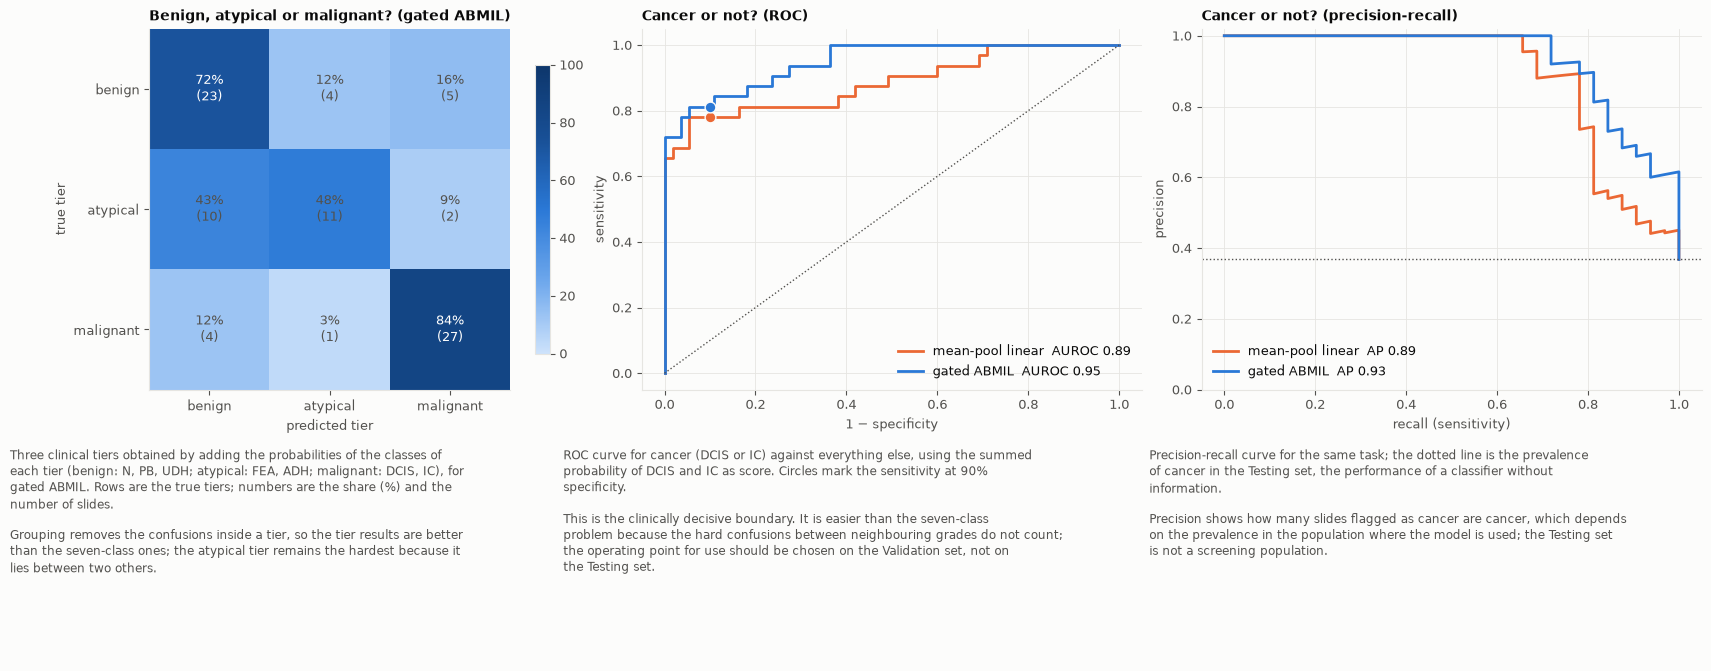

{'linear': {'AUROC': 0.886,
  'AP': 0.887,
  'sensitivity at 90% specificity': 0.781},
 'abmil': {'AUROC': 0.948,
  'AP': 0.934,
  'sensitivity at 90% specificity': 0.812}}

In [18]:
# STEP 1: Three tiers and cancer against non-cancer
clinical = plot_clinical_views(y_test, proba, classes, main='abmil')
{name: {'AUROC': round(v['cancer']['auroc'], 3), 'AP': round(v['cancer']['ap'], 3), 'sensitivity at 90% specificity': round(v['cancer']['sensitivity_at_specificity'], 3)} for name, v in clinical['views'].items()}

### 6.7 Comparison of the two models
The headline measures of both models with their intervals and single seeds, and the paired difference (attention model minus baseline) estimated on the same bootstrap resamples. An interval for the difference that contains zero means that the data do not show a difference between the models.

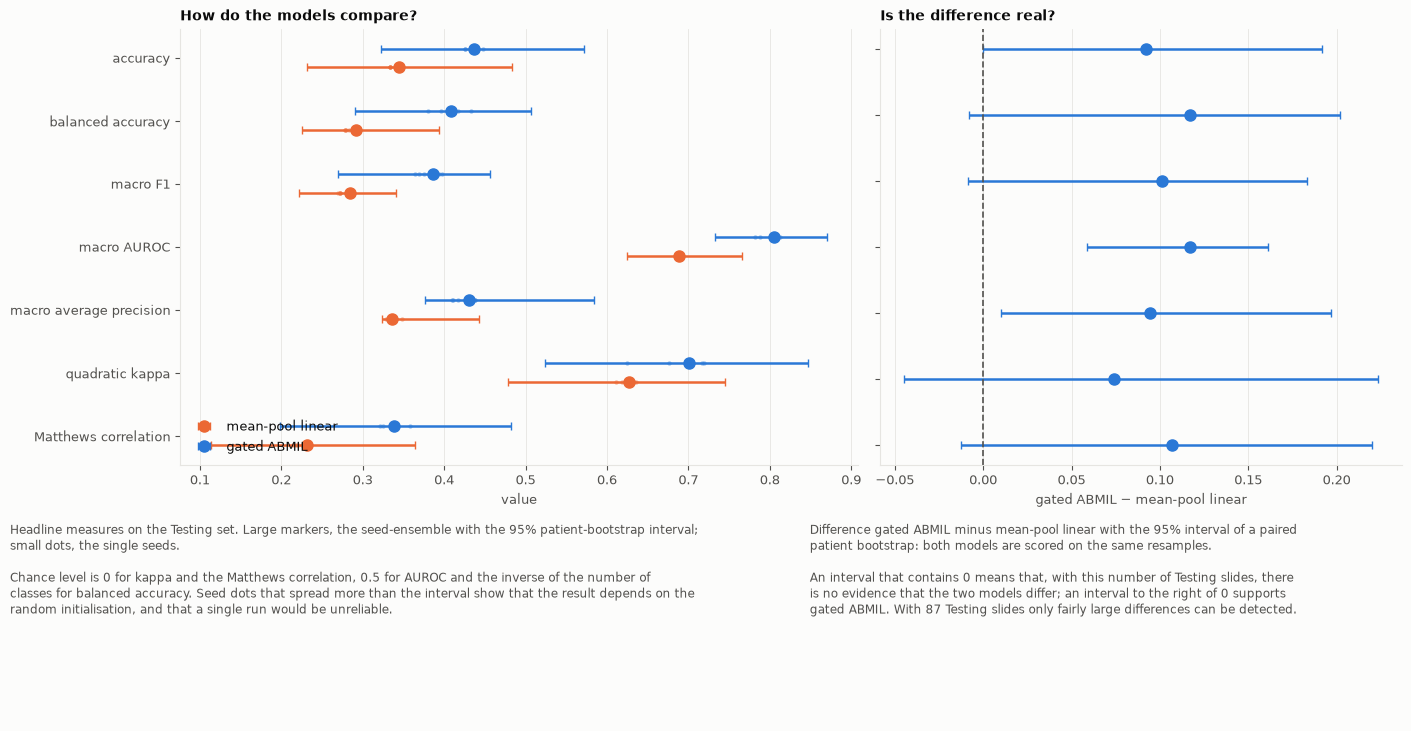

,difference,low,high,share_a_better
accuracy,0.092,0.000,0.192,0.961
balanced_accuracy,0.117,-0.008,0.202,0.964
macro_f1,0.101,-0.008,0.183,0.961
macro_auroc,0.117,0.059,0.161,1.000
macro_ap,0.094,0.010,0.197,0.987
quadratic_kappa,0.074,-0.045,0.223,0.856
mcc,0.107,-0.012,0.220,0.962


In [19]:
# STEP 1: Measures with intervals, and the paired difference
comparison = plot_model_comparison({n: intervals[n]['ci'] for n in intervals}, per_seed, paired, 'abmil', 'linear')
paired.round(3)

## 7. Interpretation: attention over the tiles
The attention weights of the attention model show which tiles it relies on. For two correctly classified Testing slides (the lowest and the highest class, with the highest confidence) and the most confident error, the weight of every tile is drawn on the slide and the six tiles with the highest weight are shown. Attention is not an explanation in the causal sense: it shows where the model looks, not why, and tiles with artefacts or staining differences can receive attention for reasons unrelated to the lesion.

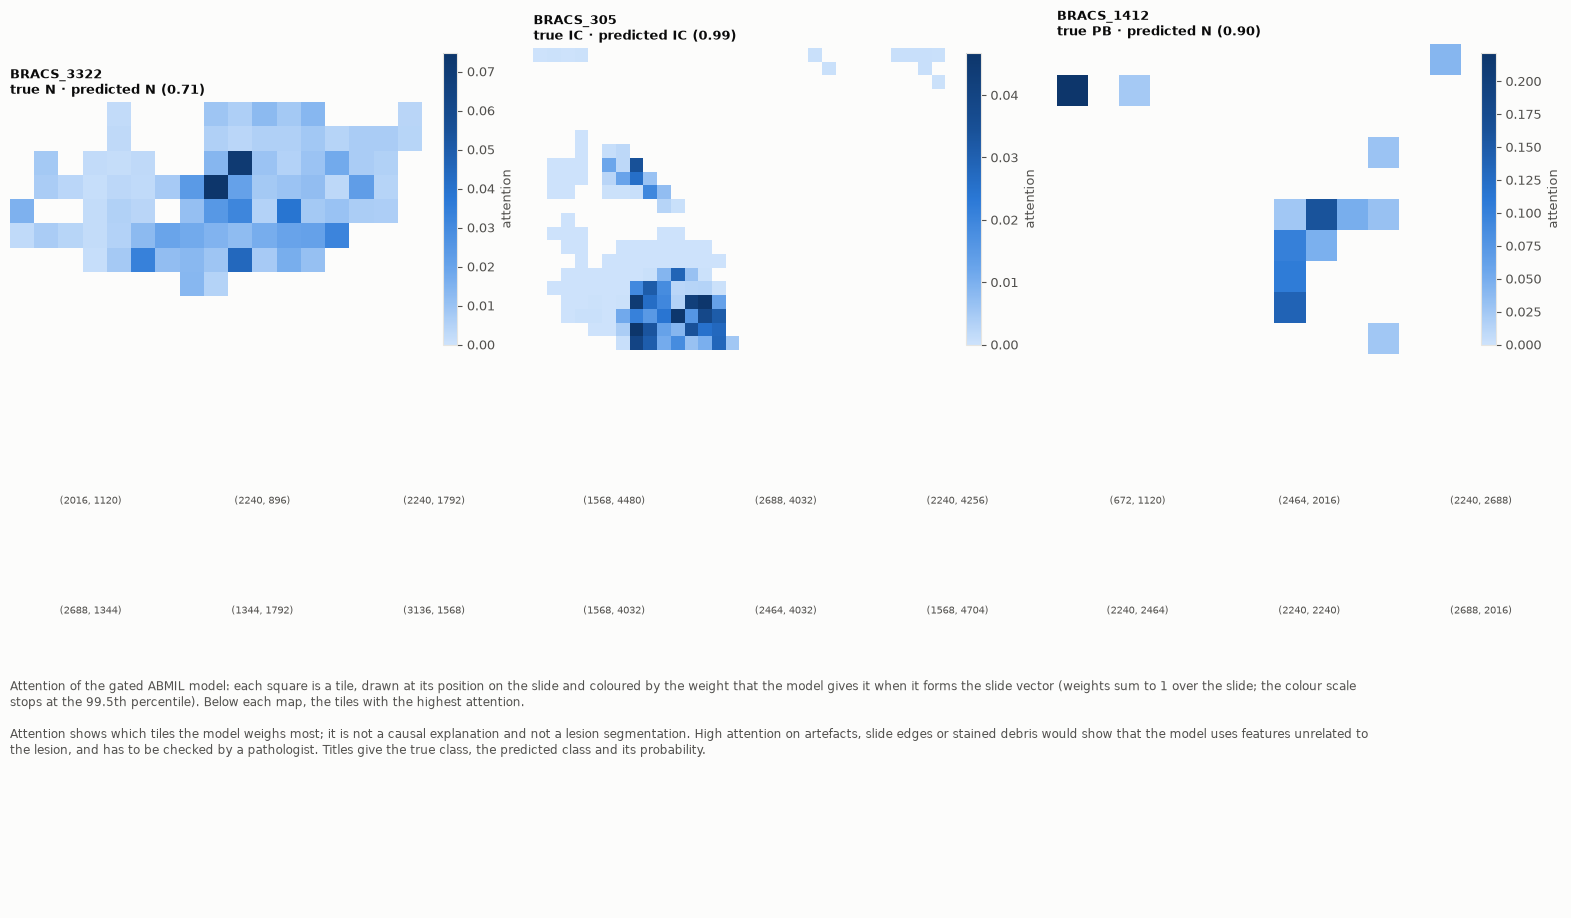

In [20]:
# STEP 1: Predictions of the attention model with class names
pred_table = predictions_table(test, classes, proba['abmil'])
correct, wrong = pred_table[pred_table['true'] == pred_table['pred']], pred_table[pred_table['true'] != pred_table['pred']]

# STEP 2: Most confident correct slide of the first and the last class, and the most confident error
shown = [correct[correct['true'] == c].sort_values('confidence')['slide'].iloc[-1] for c in (classes[0], classes[-1]) if (correct['true'] == c).any()]
shown += wrong.sort_values('confidence')['slide'].tolist()[-1:]

# STEP 3: Attention maps and top tiles (tiles are shown when the slides are available in DATA_DIR)
attention = dict(zip(test_slides, predictions['abmil']['attention']))
attention_figure = plot_attention(shown, data, attention, pred_table, DATA_DIR)

## 8. Summary and saving the classifier

### 8.1 Main results
The main measures of both models on the Testing set, as ensemble value with its 95% interval.

In [21]:
# STEP 1: Headline measures of both models
results.loc[['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'macro_auroc', 'macro_ap', 'quadratic_kappa', 'mcc', 'top2_accuracy', 'ece'], ['linear', 'abmil']]

,linear,abmil
accuracy,"0.345 [0.232, 0.484]","0.437 [0.322, 0.571]"
balanced_accuracy,"0.292 [0.225, 0.394]","0.409 [0.291, 0.506]"
macro_f1,"0.284 [0.222, 0.341]","0.386 [0.270, 0.456]"
weighted_f1,0.343,0.418
macro_auroc,"0.688 [0.625, 0.766]","0.805 [0.733, 0.870]"
macro_ap,"0.336 [0.324, 0.443]","0.431 [0.376, 0.584]"
quadratic_kappa,"0.627 [0.478, 0.745]","0.701 [0.524, 0.847]"
mcc,"0.232 [0.114, 0.364]","0.339 [0.198, 0.483]"
top2_accuracy,0.494,0.667
ece,0.218,0.169


### 8.2 Saving the best classifier
Saves the single best classifier to `classifier/classifier_model_<date-time>.pt` (set `SAVE_BEST_MODEL = False` to save nothing). The best classifier is the run with the highest **Validation** macro F1 among both models and all seeds; the Testing set plays no part in this choice, which would otherwise bias the test result. The file contains the weights, the class names of the label sheet (the output order of the model), the feature scaler fitted on the Training slides, the architecture settings, the Validation result and the configuration of the run (seeds, training arguments, selected weighting, tiling of the features, versions, device). `utils.mil_train.load_classifier` loads it again. The reported test results are those of the seed ensemble; the saved file is one model of it.

In [ ]:
# STEP 1: Everything needed to reproduce and to reuse the run
config = dict(
    seed=SEED, seeds=SEEDS, classes=classes, weighting=WEIGHTING, train_args=TRAIN_ARGS, n_boot=N_BOOT,
    features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, weights=class_weights.tolist() if class_weights is not None else None, tile_params=data['tile_params'], device=device_description(DEVICE),
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__),
    n_slides={s: int((data['table']['set'] == s).sum()) for s in ('Training', 'Validation', 'Testing')}, dropped_slides=data['missing'],
    best_epochs={n: [r['best_epoch'] for r in rs] for n, rs in runs.items()},
)

# STEP 2: Save the best classifier (chosen on the Validation set, not on the Testing set); nothing else is written
if SAVE_BEST_MODEL:
    model_path = save_best_model(runs, MODEL_DIR, config)
    print('Best classifier saved to', model_path.resolve())
else:
    print('SAVE_BEST_MODEL is False: nothing was written.')